# Лабораторная работа № 5.  Рекуррентные сети на базе LSTM

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

Геометрическая (мультипликативная) прогрессия по модулю 10

x0 случайно;
xi = (k · xi−1) mod 10, k ∈ {2, 3, 4, 7, 9}

In [54]:
import numpy as np
import torch
import torch.nn as nn

In [55]:
torch.manual_seed(42)
np.random.seed(42)

In [56]:
STEPS = [2, 3, 4, 7, 9]
SEQ_LEN = 20
N_SEQS = 1000
VOCAB = 10

In [57]:
def gen_seq(seq, k, seq_len=SEQ_LEN):
    if len(seq) == seq_len:
        return seq
    return gen_seq(np.append(seq, k * seq[-1] % 10), k, seq_len)

In [58]:
def gen_fib(seq_len=SEQ_LEN):
    res = [np.random.randint(0, 10) for _ in range(2)]
    while len(res) < seq_len:
        res.append((res[-2] + res[-1]) % 10)
    return res

In [59]:
def create_dataset(data):
    X = data[:, :-1]
    y = data[:, 1:]

    n_train = int(len(X) * 0.8)

    X_train, X_test = torch.tensor(X[:n_train]), torch.tensor(X[n_train:])
    y_train, y_test = torch.tensor(y[:n_train]), torch.tensor(y[n_train:])
    
    return (X_train, X_test, y_train, y_test)

In [60]:
datasets = {'seq': {}, 'fib': {}}

In [61]:
x0 = np.random.randint(1, 10, size=(N_SEQS, 1))

data_seq = np.array([
    gen_seq(first, np.random.choice(STEPS))
    for first in x0
])

datasets['seq']['data'] = create_dataset(data_seq)

In [62]:
data_fib = np.array([gen_fib() for _ in range(N_SEQS)])

datasets['fib']['data'] = create_dataset(data_fib)

In [63]:
class SeqLSTM(nn.Module):
    def __init__(self, hidden=64, vocab=VOCAB, emb=16, num_layers=1):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)
        self.lstm = nn.LSTM(emb, hidden, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden, vocab)
    
    def forward(self, x):
        emb = self.emb(x)
        out, state = self.lstm(emb)
        return self.fc1(out), state

In [64]:
class SeqRNN(nn.Module):
    def __init__(self, hidden=64, vocab=VOCAB, emb=16, num_layers=1):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb)
        self.lstm = nn.RNN(emb, hidden, num_layers, batch_first=True)
        self.fc1 = nn.Linear(hidden, vocab)
    
    def forward(self, x):
        emb = self.emb(x)
        out, state = self.lstm(emb)
        return self.fc1(out), state

In [65]:
NUM_EPOCHS = 15
BATCH_SIZE = 32

loss_fn = nn.CrossEntropyLoss()

for seq_name, seq_dict in datasets.items():
    
    print(f'Sequence {seq_name}')
    X_train, X_test, y_train, y_test = seq_dict['data']
    
    models = {
    'rnn': {
        'model': SeqRNN(),
        'loss_hist': [],
        'acc_hist': []
    },
    'lstm': {
        'model': SeqLSTM(),
        'loss_hist': [],
        'acc_hist': []
    },
}
    
    for model_name, m_dict in models.items():
        model = m_dict['model']
        opt = torch.optim.Adam(model.parameters(), lr=0.001)
        print(f'Parameters num for {model_name}:', sum(p.numel() for p in model.parameters()))
        
        for _ in range(NUM_EPOCHS):
            model.train()
            total_loss = 0.0
            
            batches = np.random.permutation(len(X_train))
            
            for i in range(0, len(X_train), BATCH_SIZE):
                batch = batches[i:i + BATCH_SIZE]
                opt.zero_grad()
                logits, _ = model(X_train[batch])
                loss = loss_fn(logits.reshape(-1, VOCAB), y_train[batch].reshape(-1))
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                opt.step()
                total_loss += loss.item() * len(batch)
                
            total_loss /= len(X_train)
            m_dict['loss_hist'].append(total_loss)
            
            with torch.no_grad():
                logits, _ = model(X_test)
            acc = (logits.argmax(axis=-1) == y_test).float().mean().item()
            m_dict['acc_hist'].append(acc)

        print(f'Final accuracy for {model_name}: {m_dict['acc_hist'][-1]:.4f}')
        logits.argmax(axis=-1)
    
    datasets[seq_name]['models'] = models
    print(datasets[seq_name]['models'])

Sequence seq
Parameters num for rnn: 6058
Final accuracy for rnn: 0.9647
Parameters num for lstm: 21802
Final accuracy for lstm: 0.9632
{'rnn': {'model': SeqRNN(
  (emb): Embedding(10, 16)
  (lstm): RNN(16, 64, batch_first=True)
  (fc1): Linear(in_features=64, out_features=10, bias=True)
), 'loss_hist': [2.022743000984192, 1.3073326468467712, 0.7530338430404663, 0.49191354274749755, 0.35997821927070617, 0.2802592927217484, 0.22658300638198853, 0.18944076478481292, 0.16540246725082397, 0.1487143474817276, 0.13641348153352736, 0.12707231432199478, 0.11951727241277695, 0.1134160003066063, 0.10827817171812057], 'acc_hist': [0.6200000047683716, 0.7915789484977722, 0.878947377204895, 0.9281578660011292, 0.9515789747238159, 0.9576315879821777, 0.9597368240356445, 0.9618421196937561, 0.9613158106803894, 0.9628947377204895, 0.9642105102539062, 0.9642105102539062, 0.9642105102539062, 0.9642105102539062, 0.964736819267273]}, 'lstm': {'model': SeqLSTM(
  (emb): Embedding(10, 16)
  (lstm): LSTM(16,

In [66]:
y_test.size()

torch.Size([200, 19])

In [67]:
pred = logits.argmax(dim=-1)

mask = (pred != y_test).any(dim=1)

y_test[mask].size()

torch.Size([184, 19])

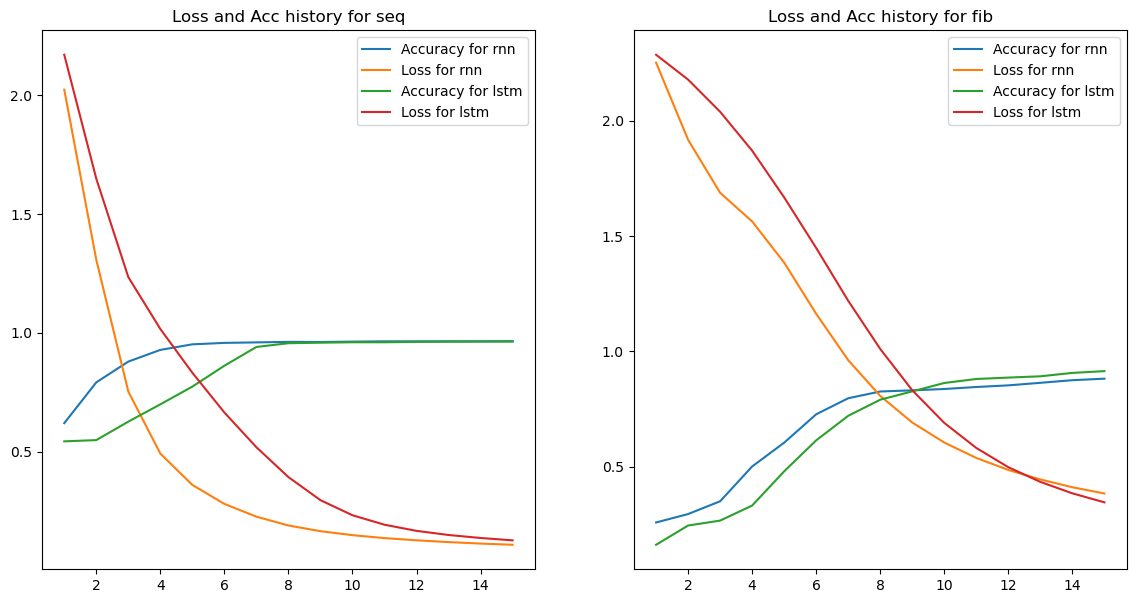

In [85]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
col = 0
for seq_name, seq_dict in datasets.items():
    models = seq_dict['models']
    for model_name, m_dict in models.items():
        axs[col].plot(range(1, NUM_EPOCHS + 1), m_dict['acc_hist'], label=f'Accuracy for {model_name}')
        axs[col].plot(range(1, NUM_EPOCHS + 1), m_dict['loss_hist'], label=f'Loss for {model_name}')
    axs[col].legend()
    axs[col].set_title(f'Loss and Acc history for {seq_name}')
    col += 1
    # axs[col].show()   

In [69]:
n_steps = 4

for _ in range(3):
    x0 = np.array([np.random.randint(0, 10)])
    k = np.random.choice(STEPS)
    seq = gen_seq(x0, k, 7)
    res = seq[:3]
    print(f'Seed: {res}')
    
    for _ in range(n_steps):
        x = torch.tensor(res).reshape(1, -1)
        logits, _ = model(x)
        num = logits[0, -1].argmax().item()
        res = np.append(res, num)
    print(f'Pred by seed with 4 steps:\n{res}')
    print(f'True:\n{seq}')

Seed: [4 6 4]
Pred by seed with 4 steps:
[4 6 4 8 4 2 0]
True:
[4 6 4 6 4 6 4]
Seed: [1 2 4]
Pred by seed with 4 steps:
[1 2 4 5 9 4 3]
True:
[1 2 4 8 6 2 4]
Seed: [5 5 5]
Pred by seed with 4 steps:
[5 5 5 0 5 5 0]
True:
[5 5 5 5 5 5 5]


## Контрольные вопросы к защите лабораторной работы
### 1. В чём заключается проблема затухающего градиента в простых RNN и почему она особенно критична для длинных последовательностей?

​
### 2. Опишите устройство ячейки LSTM: назначение вентилей забывания, входного и выходного, роль состояния ячейки ct.


### 3. Почему аддитивное обновление состояния ячейки в LSTM смягчает затухание градиента по сравнению с чисто мультипликативным обновлением скрытого состояния в простой RNN?


### 4. Как формируются обучающие пары (вход, цель) для задачи предсказания следующего элемента последовательности?


### 5.  Как устроена авторегрессионная генерация продолжения последовательности обученной сетью? Зачем передавать скрытое состояние (h,c) между шагами генерации, а не пересчитывать его заново?
